<a href="https://colab.research.google.com/github/nivethashrikm08-blip/MLA0202-FML/blob/main/exp2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Training Dataset:
     Sky Temperature Humidity    Wind Water Forecast EnjoySport
0  Sunny        Warm   Normal  Strong  Warm     Same        Yes
1  Sunny        Warm     High  Strong  Warm     Same        Yes
2  Rainy        Cold     High  Strong  Warm   Change         No
3  Sunny        Warm     High  Strong  Cool   Change        Yes

Specific Boundary (S):
['Sunny', 'Warm', '?', 'Strong', '?', '?']

General Boundary (G):
['Sunny', '?', '?', '?', '?', '?']
['?', 'Warm', '?', '?', '?', '?']


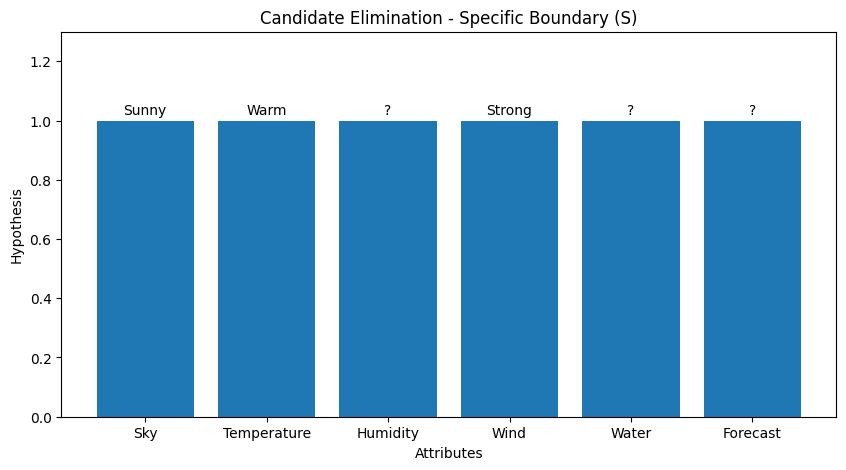

In [1]:
# EXPERIMENT 2: CANDIDATE ELIMINATION ALGORITHM

import pandas as pd

# Training dataset
data = [
    ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same', 'Yes'],
    ['Sunny', 'Warm', 'High', 'Strong', 'Warm', 'Same', 'Yes'],
    ['Rainy', 'Cold', 'High', 'Strong', 'Warm', 'Change', 'No'],
    ['Sunny', 'Warm', 'High', 'Strong', 'Cool', 'Change', 'Yes']
]

columns = [
    'Sky', 'Temperature', 'Humidity',
    'Wind', 'Water', 'Forecast', 'EnjoySport'
]

df = pd.DataFrame(data, columns=columns)

print("Training Dataset:")
print(df)

# Initialize Specific and General hypotheses
S = ['0'] * 6
G = [['?'] * 6]

# Candidate Elimination
for row in data:
    attributes = row[:-1]
    target = row[-1]

    if target == 'Yes':
        # Remove inconsistent general hypotheses
        G = [
            g for g in G
            if all(g[i] == '?' or g[i] == attributes[i]
                   for i in range(6))
        ]

        # Generalize Specific hypothesis
        for i in range(6):
            if S[i] == '0':
                S[i] = attributes[i]
            elif S[i] != attributes[i]:
                S[i] = '?'

    else:
        # Specialize general hypotheses
        new_G = []

        for g in G:
            if all(g[i] == '?' or g[i] == attributes[i]
                   for i in range(6)):
                for i in range(6):
                    if S[i] != '?' and S[i] != '0':
                        if attributes[i] != S[i]:
                            new_h = g.copy()
                            new_h[i] = S[i]
                            new_G.append(new_h)
            else:
                new_G.append(g)

        G = new_G

print("\nSpecific Boundary (S):")
print(S)

print("\nGeneral Boundary (G):")
for hypothesis in G:
    print(hypothesis)
    # GRAPH FOR EXPERIMENT 2

import matplotlib.pyplot as plt

attributes = [
    "Sky", "Temperature", "Humidity",
    "Wind", "Water", "Forecast"
]

# Final Specific hypothesis
S = ["Sunny", "Warm", "?", "Strong", "?", "?"]

# Plot Specific hypothesis
plt.figure(figsize=(10, 5))

plt.bar(attributes, [1] * len(attributes))

for i, value in enumerate(S):
    plt.text(i, 1.02, value, ha="center")

plt.xlabel("Attributes")
plt.ylabel("Hypothesis")
plt.title("Candidate Elimination - Specific Boundary (S)")
plt.ylim(0, 1.3)
plt.show()